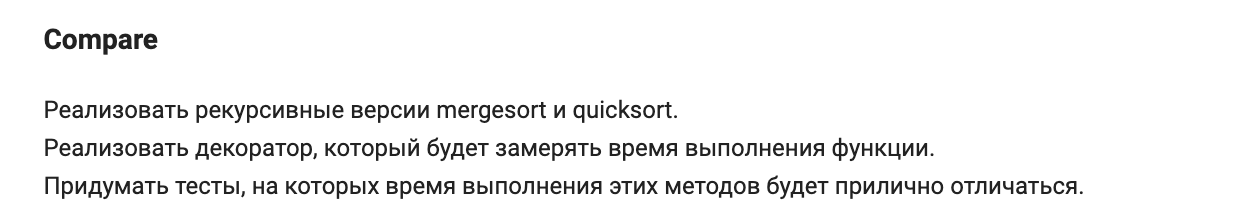

# Ход решения

**Merge Sort.** Данный алгосик работает по принципу «разделяй и властвуй». Сначала исходный массив делится на две примерно равные половины, после чего каждая половина рекурсивно делится ещё пополам, пока не останутся массивы из одного элемента, а они уже по дефолту считаются отсортированными. Затем рекурсивные вызовы начинают завершаться, и на каждом уровне происходит слияние двух отсортированных половин. Для этого используются два указателя: i для левого массива и j для правого. На каждом шаге сравниваются элементы left[i] и right[j], меньший из них добавляется в результирующий массив, а соответствующий указатель сдвигается на одну позицию. Когда один из массивов заканчивается, оставшиеся элементы второго добавляются в конец. Таким образом, небольшие отсортированные части постепенно объединяются в более крупные, пока не получится полностью отсортированный массив. И главный плюс слияния массивов таким образом - это делается за линейное время, которое зависит от суммы числа элементов в массивах.

**Quick Sort.** Данный алгоритм придерживается того же замечательного принципа "разделяй и властвуй"! Сначала выбираем последний элемент текущего подмассива в качестве опорного элемента (pivot), относительно которого будем разделять остальные элементы. В принципе можно и не последний, но нам для простоты хочется именно его взять. Для этого используем два указателя: j последовательно просматривает элементы подмассива слева направо, а i указывает на позицию, куда необходимо поставить следующий найденный элемент меньше pivot. Если arr[j] < pivot, меняем местами элементы arr[i] и arr[j], после чего увеличиваем i на единицу. Если элемент больше или равен pivot, просто продолжаем просмотр, не изменяя i. Таким образом, в левой части постепенно собираются все элементы меньше опорного, а справа остаются элементы больше или равные ему. После завершения прохода меняем pivot с элементом на позиции i, тем самым устанавливая его на окончательное место в отсортированном массиве. Затем рекурсивно применяем тот же алгоритм к левой и правой частям, не включая сам pivot, поскольку он уже находится на правильной позиции. Рекурсия завершается, когда подмассив содержит не более одного элемента. Операцию разделения массива относительно опорного элемента выносим в отдельную функцию partition, чтобы переиспользовать её в алгоритме и при визуализации его работы.

**Измерение.** Декоратор `measure_time` измеряет время через `perf_counter()` и сохраняет его в `last_elapsed`, не меняя результат функции. Для уменьшения шума берём медиану пяти замеров. Сравниваем случайные, возрастающие, убывающие и одинаковые элементы; передаём обеим функциям одинаковый массив. Алгоритмы возвращают новый список и не меняют входной.

# Граничные случаи

- Пустой массив и массив из одного элемента: возвращаем копию без сортировки.
- Повторяющиеся значения, отрицательные числа и ноль обрабатываются обычными сравнениями.
- Уже отсортированный массив — неудачный случай для нашей реализации Quick Sort, поскольку в качестве `pivot` всегда выбирается последний элемент, который оказывается максимальным. В результате все остальные элементы попадают в левую часть, а правая остаётся пустой. Вместо деления массива на две примерно равные части получаем разбиение размером `n-1` и `0`. Такая ситуация повторяется на каждом рекурсивном вызове, поэтому глубина рекурсии достигает \(O(n)\), а время работы увеличивается до \(O(n^2)\). При этом Merge Sort независимо от исходного порядка элементов сохраняет сложность \(O(n\log n)\).

- Массив одинаковых элементов — также неудачный случай для нашей реализации Quick Sort. Поскольку при разбиении используется строгое сравнение `arr[j] < pivot`, ни один элемент не удовлетворяет условию и указатель `i` не сдвигается. В результате `pivot` перемещается в начало подмассива, а остальные `n-1` элементов остаются справа. На каждой итерации размер обрабатываемого подмассива уменьшается всего на один элемент, что снова приводит к сложности \(O(n^2)\). Для решения этой проблемы можно использовать трёхстороннее разбиение, которое отдельно группирует элементы меньше, равные и больше `pivot`.
- Рекурсивный Quick Sort в Python ограничен глубиной стека; в эксперименте берём `n=700`, чтобы показать квадратичное поведение без `RecursionError` при стандартном лимите.


# Сложность алгоритмов

| Алгоритм | Лучшее время | Среднее время | Худшее время | Дополнительная память |
| --- | --- | --- | --- | --- |
| Merge Sort | $O(n\log n)$ | $O(n\log n)$ | $O(n\log n)$ | $O(n)$ |
| Quick Sort с последним `pivot` | $O(n\log n)$ | $O(n\log n)$ | $O(n^2)$ | $O(n)$ с учётом копии входа (стек: $O(\log n)$ в среднем, $O(n)$ в худшем) |

**Merge Sort.** Массив рекурсивно делится пополам, поэтому глубина рекурсии составляет около $\log_2 n$. На каждом уровне происходит слияние отсортированных частей, при котором каждый элемент обрабатывается один раз, то есть суммарная работа составляет $O(n)$. Таким образом, общая сложность равна $O(n\log n)$ независимо от исходного порядка элементов. Дополнительная память $O(n)$ необходима для хранения временных массивов при разделении и слиянии.

**Quick Sort.** Время работы зависит от выбора `pivot` и сбалансированности разбиений. Если массив каждый раз делится примерно пополам, глубина рекурсии составляет $O(\log n)$, а суммарная работа на каждом уровне — $O(n)$, поэтому получаем $O(n\log n)$. В худшем случае `pivot` постоянно оказывается минимальным или максимальным элементом, из-за чего массив делится на части размером `0` и `n-1`. Тогда количество операций пропорционально $1+2+\ldots+(n-1)=O(n^2)$. Такая ситуация возникает, например, на отсортированном массиве при выборе последнего элемента в качестве `pivot`. Стек рекурсии занимает $O(\log n)$ в среднем и $O(n)$ в худшем случае.

**Декоратор.** Измеряет время до и после выполнения функции, поэтому сам по себе требует $O(1)$ времени и $O(1)$ дополнительной памяти, не считая работы вызываемого алгоритма.

**Замечание о памяти:** `quick_sort` сначала выполняет `arr.copy()`, поэтому суммарная дополнительная память нашей реализации составляет $O(n)$, даже если сам стек рекурсии в среднем занимает только $O(\log n)$. Копирование позволяет не изменять исходный список.



# Реализация алгоритмов

In [5]:
from functools import wraps
from time import perf_counter


def merge(left, right):
    result = []
    i = j = 0

    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1

    return result + left[i:] + right[j:]


def merge_sort(arr):
    if len(arr) <= 1:
        return arr.copy()

    mid = len(arr) // 2
    left = merge_sort(arr[:mid])
    right = merge_sort(arr[mid:])
    return merge(left, right)


def partition(arr, left, right):
    pivot = arr[right]
    i = left

    for j in range(left, right):
        if arr[j] < pivot:
            arr[i], arr[j] = arr[j], arr[i]
            i += 1

    arr[i], arr[right] = arr[right], arr[i]
    return i


def quick_sort(arr):
    result = arr.copy()

    def sort(left, right):
        if left >= right:
            return

        pivot_idx = partition(result, left, right)
        sort(left, pivot_idx - 1)
        sort(pivot_idx + 1, right)

    sort(0, len(result) - 1)
    return result


def measure_time(func):
    @wraps(func)
    def wrapper(*args, **kwargs):
        start = perf_counter()
        result = func(*args, **kwargs)
        wrapper.last_elapsed = perf_counter() - start
        return result

    wrapper.last_elapsed = None
    return wrapper

# Проверка на нетривиальном примере

Возьмём массив `[7, 2, 9, 4, 1, 8, 5, 3]`.

- **Merge Sort:** разбиение до отдельных элементов, затем `[2, 7]`, `[4, 9]`, `[1, 8]`, `[3, 5]`, затем `[2, 4, 7, 9]` и `[1, 3, 5, 8]` и финальное слияние.
- **Quick Sort:** первый `pivot = 3`. После первого `partition` получим `[2, 1, 3, 4, 7, 8, 5, 9]`. Число `3` уже на окончательной позиции; два оставшихся подмассива пока не обязательно отсортированы.

In [6]:
example = [7, 2, 9, 4, 1, 8, 5, 3]
first_partition = example.copy()
pivot_idx = partition(first_partition, 0, len(first_partition) - 1)

print('Исходный массив:', example)
print('Первое разбиение Quick Sort:', first_partition, '| pivot_idx =', pivot_idx)
print('Merge Sort:', merge_sort(example))
print('Quick Sort:', quick_sort(example))
assert merge_sort(example) == quick_sort(example) == sorted(example)

Исходный массив: [7, 2, 9, 4, 1, 8, 5, 3]
Первое разбиение Quick Sort: [2, 1, 3, 4, 7, 8, 5, 9] | pivot_idx = 2
Merge Sort: [1, 2, 3, 4, 5, 7, 8, 9]
Quick Sort: [1, 2, 3, 4, 5, 7, 8, 9]


# Визуализация работы алгоритмов

**Merge Sort — делим и сливаем:**

```text
[7, 2, 9, 4, 1, 8, 5, 3]
       ↓                  разделение
[7, 2, 9, 4]  [1, 8, 5, 3]
[7, 2] [9, 4]  [1, 8] [5, 3]
[7][2][9][4]  [1][8][5][3]
       ↑                  слияние
[2, 7] [4, 9]  [1, 8] [3, 5]
[2, 4, 7, 9]   [1, 3, 5, 8]
[1, 2, 3, 4, 5, 7, 8, 9]
```

**Quick Sort — разделяем относительно `pivot`:**

```text
[7, 2, 9, 4, 1, 8, 5, 3]   pivot = 3
       ↓
[2, 1]  | 3 |  [4, 7, 8, 5, 9]
[1, 2]  | 3 |  [4, 5, 7, 8, 9]
       ↓
[1, 2, 3, 4, 5, 7, 8, 9]
```

После первого разбиения `3` стоит правильно, но `[2, 1]` и `[4, 7, 8, 5, 9]` ещё требуют рекурсивных вызовов.

# Сравнение времени

Намеренно берём Quick Sort с **последним элементом как `pivot`**. На случайных данных оба алгоритма ожидаемо имеют $O(n\log n)$, а на отсортированных и одинаковых данных Quick Sort деградирует до $O(n^2)$. Фактические миллисекунды зависят от компьютера; проверяем не конкретное время, а корректность результата и качественную разницу.


Случайный:
  Merge Sort: 2.681 мс (медиана 5 запусков)
  Quick Sort: 1.007 мс (медиана 5 запусков)

По возрастанию:
  Merge Sort: 1.956 мс (медиана 5 запусков)
  Quick Sort: 29.029 мс (медиана 5 запусков)

По убыванию:
  Merge Sort: 1.163 мс (медиана 5 запусков)
  Quick Sort: 26.555 мс (медиана 5 запусков)

Одинаковые:
  Merge Sort: 1.119 мс (медиана 5 запусков)
  Quick Sort: 18.866 мс (медиана 5 запусков)


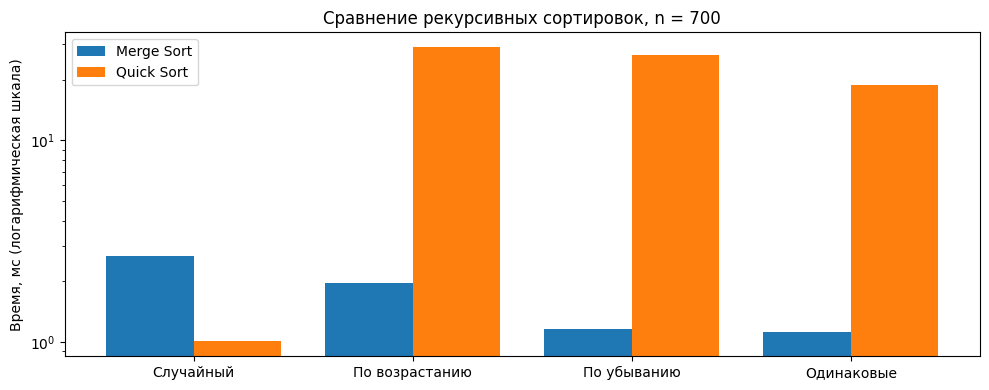

In [7]:
import random
from statistics import median
import matplotlib.pyplot as plt


@measure_time
def timed_merge_sort(arr):
    return merge_sort(arr)


@measure_time
def timed_quick_sort(arr):
    return quick_sort(arr)


n = 700
rng = random.Random(42)
cases = {
    'Случайный': rng.sample(range(n * 5), n),
    'По возрастанию': list(range(n)),
    'По убыванию': list(range(n, 0, -1)),
    'Одинаковые': [7] * n,
}
measurements = {'Merge Sort': [], 'Quick Sort': []}

for case_name, values in cases.items():
    expected = sorted(values)
    print(f'\n{case_name}:')

    for name, func in [('Merge Sort', timed_merge_sort), ('Quick Sort', timed_quick_sort)]:
        times = []

        for _ in range(5):
            assert func(values) == expected
            times.append(func.last_elapsed * 1000)

        elapsed = median(times)
        measurements[name].append(elapsed)
        print(f'  {name}: {elapsed:.3f} мс (медиана 5 запусков)')

labels = list(cases)
positions = list(range(len(labels)))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([x - 0.2 for x in positions], measurements['Merge Sort'], width=0.4, label='Merge Sort')
ax.bar([x + 0.2 for x in positions], measurements['Quick Sort'], width=0.4, label='Quick Sort')
ax.set_xticks(positions, labels)
ax.set_yscale('log')
ax.set_ylabel('Время, мс (логарифмическая шкала)')
ax.set_title(f'Сравнение рекурсивных сортировок, n = {n}')
ax.legend()
plt.tight_layout()
plt.show()

# Тесты

Проверим обе реализации:
- пустой массив, один элемент, два элемента;
- отсортированный и обратный порядок;
- дубликаты, все одинаковые значения, отрицательные числа и ноль;
- нетривиальные и случайные массивы;
- сохранность входного массива (обе функции возвращают новый список);
- корректность декоратора: возвращаемое значение и положительное измеренное время.

Ожидаемый результат в **тестах** разрешено вычислять через встроенный `sorted`: ограничений на сортировку здесь нет, они относятся к задаче `K-th`.

In [8]:
import unittest


class TestRecursiveSorts(unittest.TestCase):
    algorithms = (merge_sort, quick_sort)

    def check(self, values):
        expected = sorted(values)

        for algorithm in self.algorithms:
            with self.subTest(algorithm=algorithm.__name__, values=values[:10]):
                original = values.copy()
                self.assertEqual(algorithm(values), expected)
                self.assertEqual(values, original)

    def test_empty_and_singleton(self):
        for values in ([], [7]):
            self.check(values)

    def test_two_elements(self):
        for values in ([1, 2], [2, 1], [2, 2]):
            self.check(values)

    def test_ordered_and_reversed(self):
        self.check(list(range(100)))
        self.check(list(range(99, -1, -1)))

    def test_duplicates_and_negative(self):
        self.check([3, -2, 3, 0, -2, 8, 1, 1, 0])
        self.check([5] * 100)

    def test_nontrivial_example(self):
        self.check([7, 2, 9, 4, 1, 8, 5, 3])

    def test_random_arrays(self):
        rng = random.Random(11)
        for size in (3, 7, 20, 100, 300):
            self.check([rng.randint(-30, 30) for _ in range(size)])

    def test_decorator(self):
        @measure_time
        def double(value):
            return value * 2

        self.assertEqual(double(21), 42)
        self.assertEqual(double.__name__, 'double')
        self.assertIsInstance(double.last_elapsed, float)
        self.assertGreaterEqual(double.last_elapsed, 0)


suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestRecursiveSorts)
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful()

test_decorator (__main__.TestRecursiveSorts.test_decorator) ... ok
test_duplicates_and_negative (__main__.TestRecursiveSorts.test_duplicates_and_negative) ... ok
test_empty_and_singleton (__main__.TestRecursiveSorts.test_empty_and_singleton) ... ok
test_nontrivial_example (__main__.TestRecursiveSorts.test_nontrivial_example) ... ok
test_ordered_and_reversed (__main__.TestRecursiveSorts.test_ordered_and_reversed) ... ok
test_random_arrays (__main__.TestRecursiveSorts.test_random_arrays) ... ok
test_two_elements (__main__.TestRecursiveSorts.test_two_elements) ... ok

----------------------------------------------------------------------
Ran 7 tests in 0.033s

OK
